Intercept: 39.9358610211705
Slope: -0.15784473335365387
Mean Squared Error (MSE): 23.943662938603108
R-squared Score: 0.6059482578894348


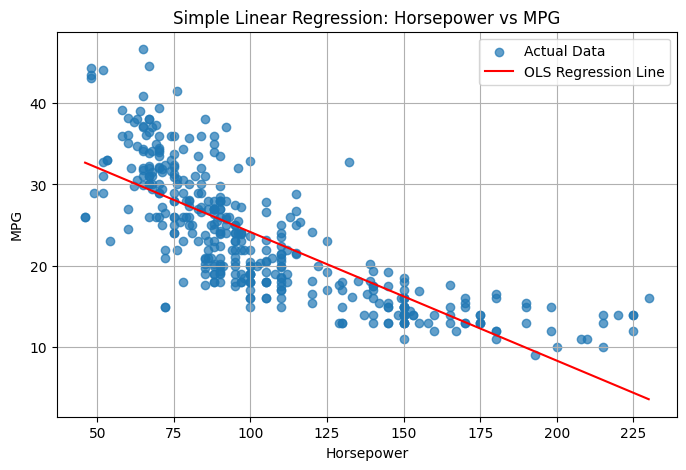

In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Load Auto MPG dataset directly from URL
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/mpg.csv"
df = pd.read_csv(url)

data = df[["horsepower", "mpg"]].copy()


data["horsepower"] = pd.to_numeric(data["horsepower"], errors="coerce")
data["mpg"] = pd.to_numeric(data["mpg"], errors="coerce")
data = data.dropna()

X = data["horsepower"].to_numpy()
y = data["mpg"].to_numpy()

# 2. Add intercept/bias term
X_matrix = np.column_stack((np.ones(len(X)), X))

w = np.linalg.inv(X_matrix.T @ X_matrix) @ X_matrix.T @ y

intercept = w[0]
slope = w[1]

print("Intercept:", intercept)
print("Slope:", slope)

# 3. Predict MPG
y_pred = X_matrix @ w


mse = np.mean((y - y_pred) ** 2)

ss_res = np.sum((y - y_pred) ** 2)
ss_tot = np.sum((y - np.mean(y)) ** 2)
r2 = 1 - (ss_res / ss_tot)

print("Mean Squared Error (MSE):", mse)
print("R-squared Score:", r2)

# 4. Plot scatter data and fitted regression line
plt.figure(figsize=(8, 5))
plt.scatter(X, y, label="Actual Data", alpha=0.7)

sorted_indices = np.argsort(X)
plt.plot(X[sorted_indices], y_pred[sorted_indices],
         color="red", label="OLS Regression Line")

plt.xlabel("Horsepower")
plt.ylabel("MPG")
plt.title("Simple Linear Regression: Horsepower vs MPG")
plt.legend()
plt.grid(True)
plt.show()
